In [1]:
import pandas as pd

# Load the restaurant survey data
df = pd.read_csv("../data/raw/public.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 410
Columns: 46


In [2]:
# Look at the first few rows
df.head()

,SHEET,CHAIN,CO_OWNED,STATE,SOUTHJ,CENTRALJ,NORTHJ,PA1,PA2,SHORE,...,FIRSTIN2,SPECIAL2,MEALS2,OPEN2R,HRSOPEN2,PSODA2,PFRY2,PENTREE2,NREGS2,NREGS112
0,46,1,0,0,0,0,0,1,0,0,...,0.08,1.0,2.0,6.5,16.5,1.03,NaN,0.94,4.0,4.0
1,49,2,0,0,0,0,0,1,0,0,...,0.05,0.0,2.0,10.0,13.0,1.01,0.89,2.35,4.0,4.0
2,506,2,1,0,0,0,0,1,0,0,...,0.25,NaN,1.0,11.0,11.0,0.95,0.74,2.33,4.0,3.0
3,56,4,1,0,0,0,0,1,0,0,...,0.15,0.0,2.0,10.0,12.0,0.92,0.79,0.87,2.0,2.0
4,61,4,1,0,0,0,0,1,0,0,...,0.15,0.0,2.0,10.0,12.0,1.01,0.84,0.95,2.0,2.0


In [3]:
# Show only the key columns
df[["STATE", "EMPFT", "EMPPT", "NMGRS"]].head()

,STATE,EMPFT,EMPPT,NMGRS
0,0,30.0,15.0,3.0
1,0,6.5,6.5,4.0
2,0,3.0,7.0,2.0
3,0,20.0,20.0,4.0
4,0,6.0,26.0,5.0


In [4]:
# Full-time-equivalent employment:
# FTE = full-time + managers + 0.5 * part-time
df["fte1"] = df["EMPFT"] + df["NMGRS"] + 0.5 * df["EMPPT"]
df["fte2"] = df["EMPFT2"] + df["NMGRS2"] + 0.5 * df["EMPPT2"]

In [5]:
# Mean FTE by state (1 = New Jersey, 0 = Pennsylvania)
df.groupby("STATE")[["fte1", "fte2"]].mean()

,fte1,fte2
STATE,,
0,23.331169,21.165584
1,20.439408,21.027429


In [6]:
# Difference-in-differences by hand
nj_change = 21.03 - 20.44   # change in New Jersey (treated)
pa_change = 21.17 - 23.33   # change in Pennsylvania (control)

did = nj_change - pa_change
print("DID estimate =", did)

DID estimate = 2.7499999999999964


In [7]:
import statsmodels.api as sm

# Balanced sample: stores with valid FTE in both waves
bal = df.dropna(subset=["fte1", "fte2"]).copy()
bal["d_fte"] = bal["fte2"] - bal["fte1"]

# Regress the change in FTE on the NJ indicator (robust SEs)
X = sm.add_constant(bal["STATE"])
result = sm.OLS(bal["d_fte"], X).fit(cov_type="HC1")

print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                  d_fte   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     4.226
Date:                Mon, 05 Oct 2026   Prob (F-statistic):             0.0405
Time:                        20:01:59   Log-Likelihood:                -1386.2
No. Observations:                 384   AIC:                             2776.
Df Residuals:                     382   BIC:                             2784.
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.2833      1.248     -1.829      0.0

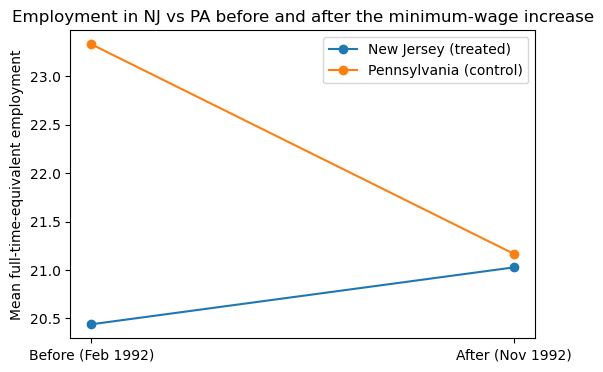

In [8]:
import matplotlib.pyplot as plt

# Mean FTE in each wave, by state
means = df.groupby("STATE")[["fte1", "fte2"]].mean()

waves = ["Before (Feb 1992)", "After (Nov 1992)"]

plt.figure(figsize=(6, 4))
plt.plot(waves, means.loc[1].values, marker="o", label="New Jersey (treated)")
plt.plot(waves, means.loc[0].values, marker="o", label="Pennsylvania (control)")

plt.ylabel("Mean full-time-equivalent employment")
plt.title("Employment in NJ vs PA before and after the minimum-wage increase")
plt.legend()
plt.show()

In [10]:
# Add control variables: chain dummies + company ownership
chain = pd.get_dummies(bal["CHAIN"], prefix="chain", drop_first=True).astype(int)

X = sm.add_constant(pd.concat([bal[["STATE", "CO_OWNED"]], chain], axis=1))
result = sm.OLS(bal["d_fte"], X).fit(cov_type="HC1")

print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                  d_fte   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                  0.016
Method:                 Least Squares   F-statistic:                     2.633
Date:                Mon, 05 Oct 2026   Prob (F-statistic):             0.0234
Time:                        20:12:25   Log-Likelihood:                -1383.4
No. Observations:                 384   AIC:                             2779.
Df Residuals:                     378   BIC:                             2803.
Df Model:                           5                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.8277      1.539     -1.188      0.2

In [11]:
# Extension: does the effect differ by chain?
chain_names = {1: "Burger King", 2: "KFC", 3: "Roy Rogers", 4: "Wendy's"}

print(f"{'Chain':<14}{'n':>5}{'DID':>9}{'SE':>7}")
for cid in [1, 2, 3, 4]:
    sub = bal[bal["CHAIN"] == cid]
    m = sm.OLS(sub["d_fte"], sm.add_constant(sub["STATE"])).fit(cov_type="HC1")
    print(f"{chain_names[cid]:<14}{len(sub):>5}{m.params['STATE']:>9.2f}{m.bse['STATE']:>7.2f}")

Chain             n      DID     SE
Burger King     159     4.39   2.53
KFC              79    -1.59   1.06
Roy Rogers       94     2.49   2.13
Wendy's          52     3.42   3.13


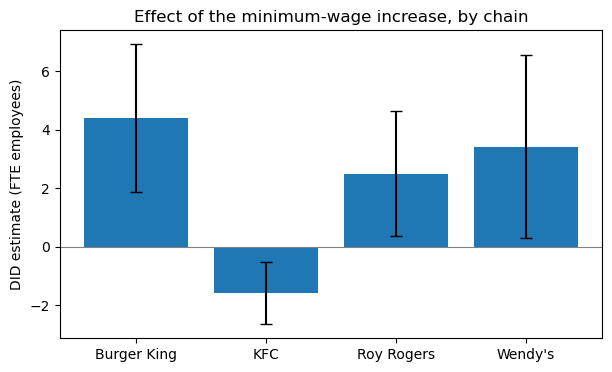

In [12]:
import matplotlib.pyplot as plt

chain_names = {1: "Burger King", 2: "KFC", 3: "Roy Rogers", 4: "Wendy's"}

dids, ses, labels = [], [], []
for cid in [1, 2, 3, 4]:
    sub = bal[bal["CHAIN"] == cid]
    m = sm.OLS(sub["d_fte"], sm.add_constant(sub["STATE"])).fit(cov_type="HC1")
    labels.append(chain_names[cid])
    dids.append(m.params["STATE"])
    ses.append(m.bse["STATE"])

plt.figure(figsize=(7, 4))
plt.bar(labels, dids, yerr=ses, capsize=4)
plt.axhline(0, color="gray", linewidth=0.8)
plt.ylabel("DID estimate (FTE employees)")
plt.title("Effect of the minimum-wage increase, by chain")
plt.savefig("chain_did.png", dpi=150, bbox_inches="tight")
plt.show()